In [ ]:
from google.colab import drive
drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")

directories = [
    "data/raw",
    "data/processed",
    "notebooks",
    "models",
    "frontend",
    "tests",
    "src/data",
    "src/ml",
    "src/graph",
    "src/api",
]

for directory in directories:
    (PROJECT / directory).mkdir(parents=True, exist_ok=True)

package_files = [
    "src/__init__.py",
    "src/data/__init__.py",
    "src/ml/__init__.py",
    "src/graph/__init__.py",
    "src/api/__init__.py",
    "tests/__init__.py",
]

for file in package_files:
    (PROJECT / file).touch(exist_ok=True)

source_files = [
    "src/data/preprocessing.py",
    "src/ml/train.py",
    "src/ml/evaluate.py",
    "src/ml/predict.py",
    "src/graph/build_graph.py",
    "src/graph/graph_features.py",
    "src/graph/suspicious_groups.py",
    "src/api/main.py",
    "src/api/schemas.py",
    "src/api/routes.py",
    "tests/test_preprocessing.py",
    "tests/test_predictions.py",
    "tests/test_graph.py",
    "data/README.md",
    "README.md",
    "Dockerfile",
    "models/.gitkeep",
]

for file in source_files:
    (PROJECT / file).touch(exist_ok=True)

print("Project structure created at:", PROJECT)

Project structure created at: /content/drive/MyDrive/FraudGraph-AI


In [ ]:
%%bash
mkdir -p /content/drive/MyDrive/FraudGraph-AI && cd /content/drive/MyDrive/FraudGraph-AI
mkdir -p data/raw data/processed notebooks models frontend tests
mkdir -p src/data src/ml src/graph src/api
touch src/__init__.py src/data/__init__.py src/ml/__init__.py src/graph/__init__.py src/api/__init__.py tests/__init__.py
touch src/data/preprocessing.py src/ml/train.py src/ml/evaluate.py src/ml/predict.py
touch src/graph/build_graph.py src/graph/graph_features.py src/graph/suspicious_groups.py
touch src/api/main.py src/api/schemas.py src/api/routes.py
touch tests/test_preprocessing.py tests/test_predictions.py tests/test_graph.py
touch data/README.md README.md Dockerfile models/.gitkeep


In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI


/content/drive/MyDrive/FraudGraph-AI


In [ ]:
%%writefile .gitignore
data/raw/
data/processed/
.venv/
.env
__pycache__/
*.py[cod]
.pytest_cache/
.ipynb_checkpoints/
node_modules/

Overwriting .gitignore


In [ ]:
%%writefile requirements.txt
pandas>=2.2,<3
numpy>=1.26,<3
scikit-learn>=1.5,<2
xgboost>=2.1,<4
imbalanced-learn>=0.12,<1
shap>=0.46,<1
joblib>=1.4,<2
matplotlib>=3.9,<4
seaborn>=0.13,<1
networkx>=3.3,<4
python-louvain>=0.16,<1
fastapi>=0.115,<1
uvicorn>=0.30,<1
pydantic>=2.8,<3
pytest>=8,<10
httpx>=0.27,<1
jupyter>=1.1,<2

Overwriting requirements.txt


In [ ]:
%pip install -q -r requirements.txt

In [ ]:
%%writefile tests/test_placeholder.py
"""Placeholder test for the initial project setup."""


def test_placeholder():
    assert True

Overwriting tests/test_placeholder.py


In [ ]:
!python -m pytest -v


============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/drive/MyDrive/FraudGraph-AI
plugins: anyio-4.15.1, typeguard-4.6.0, platformdirs-4.13.5, langsmith-0.14.12
collected 1 item                                                               

tests/test_placeholder.py::test_placeholder PASSED                       [100%]

============================== 1 passed in 0.11s ===============================


In [ ]:
!find . -maxdepth 3 -type f | sort

./creditcard (1).csv
./creditcard.csv
./data/README.md
./Dockerfile
./.gitignore
./models/.gitkeep
./.pytest_cache/CACHEDIR.TAG
./.pytest_cache/.gitignore
./.pytest_cache/README.md
./README.md
./requirements.txt
./src/api/__init__.py
./src/api/main.py
./src/api/routes.py
./src/api/schemas.py
./src/data/__init__.py
./src/data/preprocessing.py
./src/graph/build_graph.py
./src/graph/graph_features.py
./src/graph/__init__.py
./src/graph/suspicious_groups.py
./src/__init__.py
./src/ml/evaluate.py
./src/ml/__init__.py
./src/ml/predict.py
./src/ml/train.py
./tests/__init__.py
./tests/__pycache__/__init__.cpython-313.pyc
./tests/__pycache__/test_graph.cpython-313-pytest-8.4.2.pyc
./tests/__pycache__/test_placeholder.cpython-313-pytest-8.4.2.pyc
./tests/__pycache__/test_predictions.cpython-313-pytest-8.4.2.pyc
./tests/__pycache__/test_preprocessing.cpython-313-pytest-8.4.2.pyc
./tests/test_graph.py
./tests/test_placeholder.py
./tests/test_predictions.py
./tests/test_preprocessing.py


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle (2).json


In [ ]:
from pathlib import Path
import os
import shutil

# Configure Kaggle directory
kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)
destination = kaggle_dir / "kaggle.json"

# Try to find the file from the 'uploaded' variable or the absolute path
source = None
candidates = [
    Path("/content/kaggle.json"),
    Path("/content/kaggle (2).json"),
    Path("kaggle.json"),
    Path("kaggle (2).json"),
]

# Find the first candidate that exists
for p in candidates:
    if p.exists():
        source = p
        break

if source:
    shutil.copy2(source, destination)
    print(f"Copied {source.name} to {destination}")
elif 'uploaded' in globals() and uploaded:
    # Fallback: Write directly from the uploaded dictionary
    filename = list(uploaded.keys())[0]
    with open(destination, "wb") as f:
        f.write(uploaded[filename])
    print(f"Created kaggle.json from in-memory upload: {filename}")
else:
    raise FileNotFoundError("Please upload kaggle.json again.")

os.chmod(destination, 0o600)
print("Kaggle credentials configured successfully! ✅")

Copied kaggle.json to /root/.kaggle/kaggle.json
Kaggle credentials configured successfully! ✅


In [ ]:
!kaggle --version
!kaggle datasets list -s creditcardfraud

Kaggle CLI 2.0.2
ref                                   title                                      size  lastUpdated                 downloadCount  voteCount  usabilityRating  
------------------------------------  -----------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
isaikumar/creditcardfraud             Credit Card Fraud Detection Dataset    69076754  2018-05-05 09:38:01.897000           7948         87  0.47058824       
soltechhub/creditcardfraud            CreditCardFraud                           17140  2023-10-03 15:06:03.990000            127          3  0.23529412       
jeffersonvalandro/creditcardfraud     creditcardfraud                        69155672  2023-12-24 00:56:28.763000             56          0  0.29411766       
sumitchavda/creditcardfraud           creditcardfraud                         1831927  2025-01-13 09:44:45.740000             33          1  0.11764706       
melihtakyaci/creditcardfraud 

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI

!kaggle datasets download -d mlg-ulb/creditcardfraud -p data/raw --unzip

/content/drive/MyDrive/FraudGraph-AI
Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 163MB/s]



In [ ]:
from pathlib import Path

dataset = Path("/content/drive/MyDrive/FraudGraph-AI/data/raw/creditcard.csv")

if dataset.exists():
    print("✅ Dataset downloaded successfully!")
    print(f"File size: {dataset.stat().st_size / (1024**2):.2f} MB")
else:
    print("❌ Dataset not found. Check the previous cell's output.")

✅ Dataset downloaded successfully!
File size: 143.84 MB


In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI

/content/drive/MyDrive/FraudGraph-AI


In [ ]:
%%writefile src/data/preprocessing.py
"""Preprocessing for the Kaggle Credit Card Fraud dataset.

All transformers are fit on the training split only. The test split is
never resampled.
"""

from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

RANDOM_SEED: int = 42
TARGET_COL: str = "Class"
SCALE_COLS: list[str] = ["Time", "Amount"]
FEATURE_COLS: list[str] = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount"]
EXPECTED_COLS: list[str] = [*FEATURE_COLS, TARGET_COL]


@dataclass(frozen=True)
class PreparedData:
    """Train/test splits with the scaler fitted on the training split."""

    X_train: pd.DataFrame
    X_test: pd.DataFrame
    y_train: pd.Series
    y_test: pd.Series
    scaler: RobustScaler


def load_raw(path: str | Path) -> pd.DataFrame:
    """Load the raw CSV and validate its schema.

    Raises:
        ValueError: If expected columns are missing or any value is null.
    """
    df = pd.read_csv(path)
    missing = [c for c in EXPECTED_COLS if c not in df.columns]
    if missing:
        raise ValueError(f"Missing expected columns: {missing}")
    if df[EXPECTED_COLS].isnull().any().any():
        raise ValueError("Dataset contains null values.")
    return df[EXPECTED_COLS].copy()


def split_data(
    df: pd.DataFrame,
    test_size: float = 0.2,
    seed: int = RANDOM_SEED,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """Stratified train/test split on the target column."""
    X = df[FEATURE_COLS]
    y = df[TARGET_COL]
    return train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=seed
    )


def fit_scaler(X_train: pd.DataFrame) -> RobustScaler:
    """Fit a RobustScaler on Time and Amount of the training data only."""
    scaler = RobustScaler()
    scaler.fit(X_train[SCALE_COLS])
    return scaler


def apply_scaler(X: pd.DataFrame, scaler: RobustScaler) -> pd.DataFrame:
    """Return a copy of X with Time and Amount scaled by a fitted scaler."""
    X_out = X.copy()
    X_out[SCALE_COLS] = scaler.transform(X_out[SCALE_COLS])
    return X_out


def prepare_data(
    path: str | Path,
    test_size: float = 0.2,
    seed: int = RANDOM_SEED,
) -> PreparedData:
    """Load, split, and scale the dataset.

    The scaler is fit on the training split and applied to both splits.
    """
    df = load_raw(path)
    X_train, X_test, y_train, y_test = split_data(df, test_size, seed)
    scaler = fit_scaler(X_train)
    return PreparedData(
        X_train=apply_scaler(X_train, scaler),
        X_test=apply_scaler(X_test, scaler),
        y_train=y_train,
        y_test=y_test,
        scaler=scaler,
    )

Overwriting src/data/preprocessing.py


In [ ]:
%%writefile tests/test_preprocessing.py
"""Tests for src/data/preprocessing.py."""

import numpy as np
import pandas as pd
import pytest

from src.data.preprocessing import (
    EXPECTED_COLS,
    SCALE_COLS,
    TARGET_COL,
    apply_scaler,
    fit_scaler,
    load_raw,
    split_data,
)


@pytest.fixture
def synthetic_df() -> pd.DataFrame:
    rng = np.random.default_rng(0)
    n = 2000
    df = pd.DataFrame(rng.normal(size=(n, len(EXPECTED_COLS))), columns=EXPECTED_COLS)
    df["Amount"] = rng.exponential(scale=80, size=n)
    df["Time"] = np.arange(n, dtype=float)
    df[TARGET_COL] = 0
    df.loc[rng.choice(n, size=20, replace=False), TARGET_COL] = 1
    return df


def test_split_is_stratified(synthetic_df: pd.DataFrame) -> None:
    _, _, y_train, y_test = split_data(synthetic_df)
    assert y_train.mean() == pytest.approx(y_test.mean(), abs=0.002)


def test_split_is_deterministic(synthetic_df: pd.DataFrame) -> None:
    a = split_data(synthetic_df)
    b = split_data(synthetic_df)
    pd.testing.assert_frame_equal(a[0], b[0])
    pd.testing.assert_frame_equal(a[1], b[1])


def test_split_sizes_and_no_overlap(synthetic_df: pd.DataFrame) -> None:
    X_train, X_test, _, _ = split_data(synthetic_df, test_size=0.2)
    assert len(X_test) == 400
    assert len(X_train) + len(X_test) == len(synthetic_df)
    assert set(X_train.index).isdisjoint(X_test.index)


def test_scaler_fit_on_train_only(synthetic_df: pd.DataFrame) -> None:
    X_train, X_test, _, _ = split_data(synthetic_df)
    scaler = fit_scaler(X_train)
    np.testing.assert_allclose(scaler.center_, X_train[SCALE_COLS].median().to_numpy())
    # Test split is transformed with train statistics, so its median is not forced to 0.
    scaled_test = apply_scaler(X_test, scaler)
    assert scaled_test["Amount"].median() != pytest.approx(0.0, abs=1e-12)


def test_apply_scaler_does_not_mutate_input(synthetic_df: pd.DataFrame) -> None:
    X_train, _, _, _ = split_data(synthetic_df)
    original = X_train.copy()
    apply_scaler(X_train, fit_scaler(X_train))
    pd.testing.assert_frame_equal(X_train, original)


def test_load_raw_rejects_missing_columns(tmp_path) -> None:
    path = tmp_path / "bad.csv"
    pd.DataFrame({"Time": [0.0], "Amount": [1.0]}).to_csv(path, index=False)
    with pytest.raises(ValueError, match="Missing expected columns"):
        load_raw(path)

Overwriting tests/test_preprocessing.py


In [ ]:
!python -m pytest tests/test_preprocessing.py -v

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/drive/MyDrive/FraudGraph-AI
plugins: anyio-4.15.1, typeguard-4.6.0, platformdirs-4.13.5, langsmith-0.14.12
collected 6 items                                                              

tests/test_preprocessing.py::test_split_is_stratified PASSED             [ 16%]
tests/test_preprocessing.py::test_split_is_deterministic PASSED          [ 33%]
tests/test_preprocessing.py::test_split_sizes_and_no_overlap PASSED      [ 50%]
tests/test_preprocessing.py::test_scaler_fit_on_train_only PASSED        [ 66%]
tests/test_preprocessing.py::test_apply_scaler_does_not_mutate_input PASSED [ 83%]
tests/test_preprocessing.py::test_load_raw_rejects_missing_columns PASSED [100%]

============================== 6 passed in 1.82s ===============================


In [ ]:
from src.data.preprocessing import prepare_data

data = prepare_data("data/raw/creditcard.csv")
print("Train:", data.X_train.shape, "fraud:", int(data.y_train.sum()))
print("Test: ", data.X_test.shape, "fraud:", int(data.y_test.sum()))
print("Scaler center (Time, Amount):", data.scaler.center_)

Train: (227845, 30) fraud: 394
Test:  (56962, 30) fraud: 98
Scaler center (Time, Amount): [8.4805e+04 2.2000e+01]


In [ ]:
from src.data.preprocessing import load_raw, TARGET_COL

df = load_raw("data/raw/creditcard.csv")

print("Dataset shape:", df.shape)

print("\nTransaction counts:")
print(df[TARGET_COL].value_counts())

print(f"\nFraud rate: {df[TARGET_COL].mean():.4%}")

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTransaction amount statistics:")
print(df.groupby(TARGET_COL)["Amount"].describe())

Dataset shape: (284807, 31)

Transaction counts:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud rate: 0.1727%

Duplicate rows: 1081

Transaction amount statistics:
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


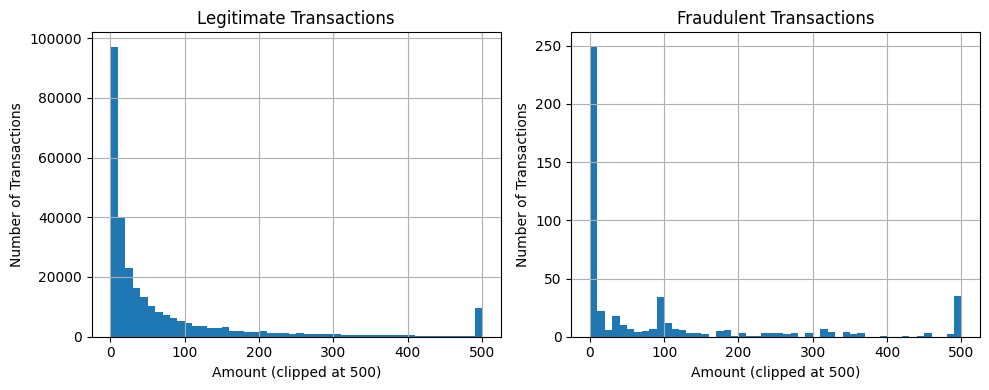

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

df[df["Class"] == 0]["Amount"].clip(upper=500).hist(
    bins=50, ax=axes[0]
)
axes[0].set_title("Legitimate Transactions")
axes[0].set_xlabel("Amount (clipped at 500)")
axes[0].set_ylabel("Number of Transactions")

df[df["Class"] == 1]["Amount"].clip(upper=500).hist(
    bins=50, ax=axes[1]
)
axes[1].set_title("Fraudulent Transactions")
axes[1].set_xlabel("Amount (clipped at 500)")
axes[1].set_ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

In [ ]:
%%writefile src/ml/evaluate.py

import numpy as np

from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)


def find_best_threshold(y_true, y_proba):
    """Find the threshold that maximizes F1 on training predictions."""

    precision, recall, thresholds = precision_recall_curve(
        y_true, y_proba
    )

    f1 = (
        2 * precision[:-1] * recall[:-1]
        / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    )

    return float(thresholds[int(np.argmax(f1))])


def compute_metrics(y_true, y_proba, threshold):
    """Calculate fraud classification metrics."""

    y_pred = (y_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "pr_auc": float(average_precision_score(y_true, y_proba)),
        "roc_auc": float(roc_auc_score(y_true, y_proba)),
        "precision": float(
            precision_score(y_true, y_pred, zero_division=0)
        ),
        "recall": float(
            recall_score(y_true, y_pred, zero_division=0)
        ),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "threshold": float(threshold),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


print("Evaluation functions saved successfully!")

Overwriting src/ml/evaluate.py


In [ ]:
%pip install -q xgboost imbalanced-learn joblib

In [ ]:
%%writefile src/ml/train.py

import json
from pathlib import Path

import joblib
import numpy as np
import sklearn
import xgboost

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.base import BaseEstimator, clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from xgboost import XGBClassifier

from src.data.preprocessing import (
    FEATURE_COLS,
    RANDOM_SEED,
    prepare_data,
)

from src.ml.evaluate import (
    compute_metrics,
    find_best_threshold,
)


N_SPLITS = 5


def build_candidates(y_train, seed=RANDOM_SEED):
    """Create three candidate models."""

    positives = int(y_train.sum())
    negatives = len(y_train) - positives

    scale_pos_weight = negatives / positives

    def make_xgb(**kwargs):
        return XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.1,
            tree_method="hist",
            eval_metric="aucpr",
            random_state=seed,
            n_jobs=-1,
            **kwargs,
        )

    return {
        "logreg_balanced": LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=seed,
        ),

        "xgb_weighted": make_xgb(
            scale_pos_weight=scale_pos_weight
        ),

        "xgb_smote": ImbPipeline([
            ("smote", SMOTE(random_state=seed)),
            ("clf", make_xgb()),
        ]),
    }


def cross_validate_candidates(
    candidates,
    X_train,
    y_train,
    seed=RANDOM_SEED,
):
    """Generate out-of-fold probabilities using training data only."""

    cv = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=seed,
    )

    oof = {}

    for name, model in candidates.items():

        probabilities = cross_val_predict(
            clone(model),
            X_train,
            y_train,
            cv=cv,
            method="predict_proba",
            n_jobs=1,
        )

        oof[name] = probabilities[:, 1]

        score = average_precision_score(
            y_train,
            oof[name],
        )

        print(f"{name}: OOF PR-AUC = {score:.4f}")

    return oof


def run_training(
    data_path="data/raw/creditcard.csv",
    model_dir="models",
    seed=RANDOM_SEED,
):
    """Train, compare, evaluate, and save the selected model."""

    data = prepare_data(data_path, seed=seed)

    X_train = data.X_train
    y_train = data.y_train.to_numpy()

    candidates = build_candidates(y_train, seed)

    # Compare models using training-only cross-validation.
    oof = cross_validate_candidates(
        candidates,
        X_train,
        y_train,
        seed,
    )

    cv_pr_auc = {
        name: float(
            average_precision_score(y_train, probabilities)
        )
        for name, probabilities in oof.items()
    }

    best_name = max(cv_pr_auc, key=cv_pr_auc.get)

    # Choose the decision threshold using OOF training predictions.
    threshold = find_best_threshold(
        y_train,
        oof[best_name],
    )

    print(f"\nSelected model: {best_name}")
    print(f"Selected threshold: {threshold:.6f}")

    # Fit the selected model on the complete training split.
    final_model = clone(candidates[best_name])

    final_model.fit(X_train, y_train)

    # Evaluate on the untouched test split exactly once.
    test_probabilities = final_model.predict_proba(
        data.X_test
    )[:, 1]

    test_metrics = compute_metrics(
        data.y_test.to_numpy(),
        test_probabilities,
        threshold,
    )

    print("\nFinal test metrics:")
    print(json.dumps(test_metrics, indent=2))

    # Save model and preprocessing information.
    model_dir = Path(model_dir)
    model_dir.mkdir(parents=True, exist_ok=True)

    joblib.dump(
        {
            "model": final_model,
            "scaler": data.scaler,
            "threshold": threshold,
            "feature_cols": FEATURE_COLS,
        },
        model_dir / "transaction_model.joblib",
    )

    metadata = {
        "selected_model": best_name,
        "random_seed": seed,
        "threshold": threshold,
        "threshold_source": (
            "Maximum F1 on out-of-fold training predictions"
        ),
        "cv_pr_auc": cv_pr_auc,
        "test_metrics": test_metrics,
        "n_train": int(len(y_train)),
        "n_test": int(len(data.y_test)),
        "feature_cols": FEATURE_COLS,
        "versions": {
            "scikit-learn": sklearn.__version__,
            "xgboost": xgboost.__version__,
        },
    }

    with open(
        model_dir / "model_metadata.json",
        "w",
    ) as file:
        json.dump(metadata, file, indent=2)

    print("\nModel and metadata saved successfully!")

    return metadata


if __name__ == "__main__":
    run_training()

Overwriting src/ml/train.py


In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI

/content/drive/MyDrive/FraudGraph-AI


In [ ]:
from src.ml.train import run_training

metadata = run_training()

KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving FraudGraph_AI_Phase2_Completion.zip to FraudGraph_AI_Phase2_Completion.zip


In [ ]:
from google.colab import drive
from pathlib import Path
import zipfile

# Mount Google Drive
drive.mount("/content/drive")

# Find the uploaded ZIP file
possible_paths = [
    Path("/content/FraudGraph_AI_Phase2_Completion.zip"),
    Path("FraudGraph_AI_Phase2_Completion.zip"),
    Path("/content") / "FraudGraph_AI_Phase2_Completion.zip",
]

ZIP_PATH = next((p.resolve() for p in possible_paths if p.exists()), None)

if ZIP_PATH is None:
    matches = list(Path("/content").rglob("FraudGraph_AI_Phase2_Completion.zip"))
    if matches:
        ZIP_PATH = matches[0]

if ZIP_PATH is None:
    raise FileNotFoundError(
        "ZIP file not found. Run files.upload() again and select the ZIP."
    )

# Existing project folder
PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")
PROJECT.mkdir(parents=True, exist_ok=True)

# Extract only the Phase 2 files into the project
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for member in archive.namelist():
        if member.startswith("FraudGraph-AI/"):
            relative_path = Path(member).relative_to("FraudGraph-AI")
            if relative_path.parts:
                archive.extract(member, "/content/drive/MyDrive")

print("ZIP found:", ZIP_PATH)
print("Phase 2 files extracted!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP found: /content/drive/My Drive/FraudGraph-AI/FraudGraph_AI_Phase2_Completion.zip
Phase 2 files extracted!


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")

files_to_check = [
    "src/ml/train.py",
    "src/ml/evaluate.py",
    "notebooks/02_ml_training.ipynb",
    "tests/test_evaluate.py",
]

for filename in files_to_check:
    path = PROJECT / filename
    print(
        "✅ FOUND" if path.exists() else "❌ MISSING",
        filename
    )

✅ FOUND src/ml/train.py
✅ FOUND src/ml/evaluate.py
✅ FOUND notebooks/02_ml_training.ipynb
✅ FOUND tests/test_evaluate.py


In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI

!python -m pytest tests/test_evaluate.py -v

/content/drive/MyDrive/FraudGraph-AI
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/drive/MyDrive/FraudGraph-AI
plugins: anyio-4.15.1, typeguard-4.6.0, platformdirs-4.13.5, langsmith-0.14.12
collected 4 items                                                              

tests/test_evaluate.py::test_compute_metrics_returns_expected_keys PASSED [ 25%]
tests/test_evaluate.py::test_threshold_f_beta_is_valid PASSED            [ 50%]
tests/test_evaluate.py::test_cost_threshold_is_valid PASSED              [ 75%]
tests/test_evaluate.py::test_invalid_threshold_objective_rejected PASSED [100%]

============================== 4 passed in 2.12s ===============================


In [ ]:
!pip install pytest

In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI

!python -m src.ml.train

/content/drive/MyDrive/FraudGraph-AI
logreg_balanced: OOF PR-AUC = 0.7478
random_forest_balanced: OOF PR-AUC = 0.8496
xgb_weighted: OOF PR-AUC = 0.8507
xgb_smote: OOF PR-AUC = 0.8469

Cross-validation comparison (ranked by PR-AUC):
                 model  oof_pr_auc
          xgb_weighted    0.850661
random_forest_balanced    0.849626
             xgb_smote    0.846881
       logreg_balanced    0.747774

Selected model: xgb_weighted
Threshold objective: f_beta; threshold=0.32479715

Final test metrics (test evaluated once):
{
  "pr_auc": 0.8878838372033735,
  "roc_auc": 0.9698702884361399,
  "precision": 0.8645833333333334,
  "recall": 0.8469387755102041,
  "f1": 0.8556701030927835,
  "threshold": 0.3247971534729004,
  "tn": 56851,
  "fp": 13,
  "fn": 15,
  "tp": 83,
  "confusion_matrix": [
    [
      56851,
      13
    ],
    [
      15,
      83
    ]
  ]
}

Saved: models/transaction_model.joblib
Saved: models/model_metadata.json


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")

for filename in [
    "models/transaction_model.joblib",
    "models/model_metadata.json",
    "data/processed/X_train.csv",
    "data/processed/X_test.csv",
    "data/processed/y_train.csv",
    "data/processed/y_test.csv",
]:
    path = PROJECT / filename
    print(("✅ FOUND" if path.exists() else "❌ MISSING"), filename)

✅ FOUND models/transaction_model.joblib
✅ FOUND models/model_metadata.json
✅ FOUND data/processed/X_train.csv
✅ FOUND data/processed/X_test.csv
✅ FOUND data/processed/y_train.csv
✅ FOUND data/processed/y_test.csv


In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI

!python -m pytest tests/test_evaluate.py -v

/content/drive/MyDrive/FraudGraph-AI
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/drive/MyDrive/FraudGraph-AI
plugins: anyio-4.15.1, typeguard-4.6.0, platformdirs-4.13.5, langsmith-0.14.12
collected 4 items                                                              

tests/test_evaluate.py::test_compute_metrics_returns_expected_keys PASSED [ 25%]
tests/test_evaluate.py::test_threshold_f_beta_is_valid PASSED            [ 50%]
tests/test_evaluate.py::test_cost_threshold_is_valid PASSED              [ 75%]
tests/test_evaluate.py::test_invalid_threshold_objective_rejected PASSED [100%]

============================== 4 passed in 2.10s ===============================


In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI

!python -m src.ml.train

/content/drive/MyDrive/FraudGraph-AI
logreg_balanced: OOF PR-AUC = 0.7478
random_forest_balanced: OOF PR-AUC = 0.8496
xgb_weighted: OOF PR-AUC = 0.8507
xgb_smote: OOF PR-AUC = 0.8469

Cross-validation comparison (ranked by PR-AUC):
                 model  oof_pr_auc
          xgb_weighted    0.850661
random_forest_balanced    0.849626
             xgb_smote    0.846881
       logreg_balanced    0.747774

Selected model: xgb_weighted
Threshold objective: f_beta; threshold=0.32479715

Final test metrics (test evaluated once):
{
  "pr_auc": 0.8878838372033735,
  "roc_auc": 0.9698702884361399,
  "precision": 0.8645833333333334,
  "recall": 0.8469387755102041,
  "f1": 0.8556701030927835,
  "threshold": 0.3247971534729004,
  "tn": 56851,
  "fp": 13,
  "fn": 15,
  "tp": 83,
  "confusion_matrix": [
    [
      56851,
      13
    ],
    [
      15,
      83
    ]
  ]
}

Saved: models/transaction_model.joblib
Saved: models/model_metadata.json


In [ ]:
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve, average_precision_score

import pandas as pd
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")

X_train = pd.read_csv(PROJECT / "data/processed/X_train.csv")
y_train = pd.read_csv(PROJECT / "data/processed/y_train.csv").squeeze()

# Convert labels to a NumPy array
y_train = np.asarray(y_train).ravel()

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("Fraud cases:", int(y_train.sum()))
print("Feature columns:", list(X_train.columns))

X_train shape: (227845, 30)
y_train shape: (227845,)
Fraud cases: 394
Feature columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer

numeric_to_scale = ["Time", "Amount"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "scaled",
            SklearnPipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", RobustScaler())
            ]),
            numeric_to_scale
        )
    ],
    remainder="passthrough"
)

# Class imbalance ratio
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count

models = {
    "Logistic Regression": ImbPipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": ImbPipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost Weighted": ImbPipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.05,
            scale_pos_weight=scale_pos_weight,
            eval_metric="aucpr",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost + SMOTE": ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.05,
            eval_metric="aucpr",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

Generating curve for Logistic Regression...
Generating curve for Random Forest...
Generating curve for XGBoost Weighted...
Generating curve for XGBoost + SMOTE...


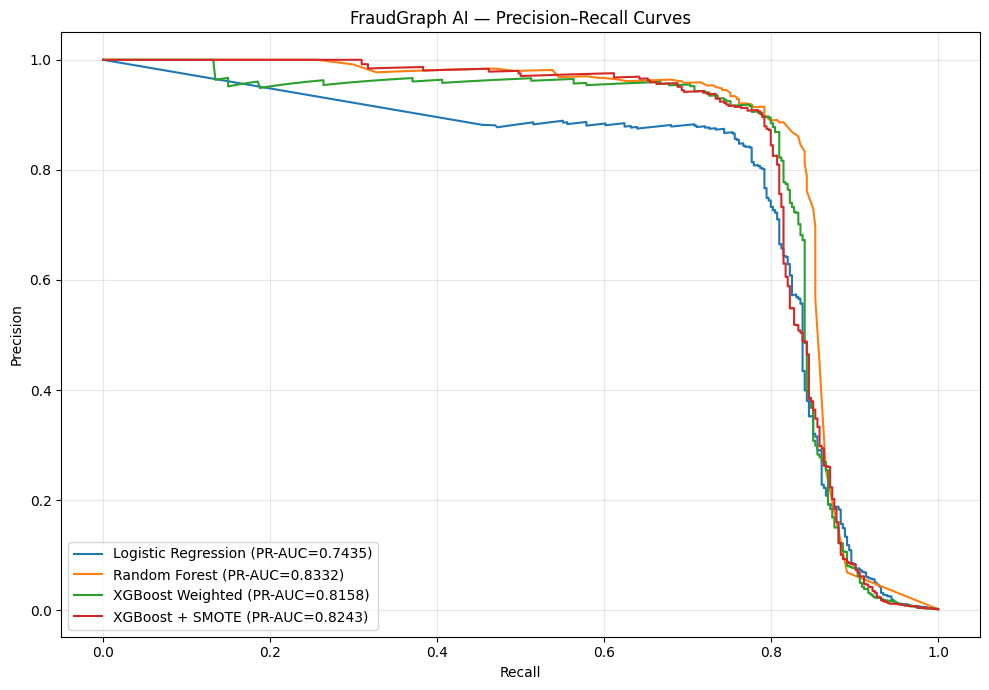

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

plt.figure(figsize=(10, 7))

for name, model in models.items():
    print(f"Generating curve for {name}...")

    oof_probabilities = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_train,
        oof_probabilities
    )

    pr_auc = average_precision_score(
        y_train,
        oof_probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (PR-AUC={pr_auc:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("FraudGraph AI — Precision–Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
!pip -q install shap

In [ ]:
import joblib
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")

model_path = PROJECT / "models/transaction_model.joblib"

model = joblib.load(model_path)

X_train = pd.read_csv(PROJECT / "data/processed/X_train.csv")

print("Model loaded successfully.")
print("Training data shape:", X_train.shape)

Model loaded successfully.
Training data shape: (227845, 30)


Classifier: XGBClassifier
Data shape: (500, 30)


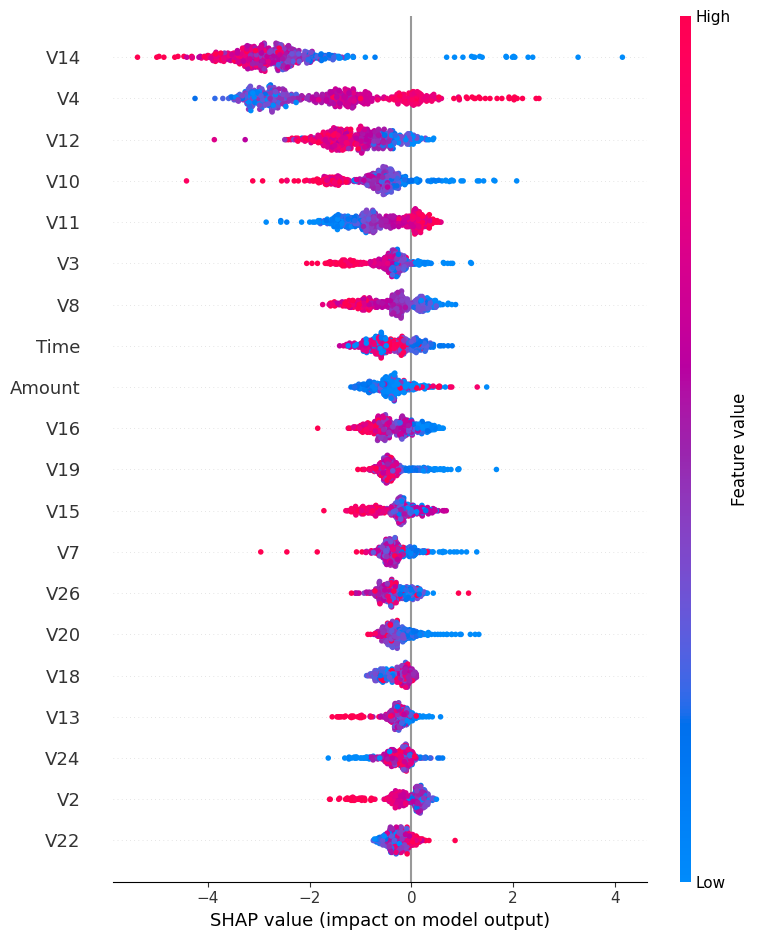

In [ ]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")

# Load training data
X_train = pd.read_csv(PROJECT / "data/processed/X_train.csv")

# Load the correct pipeline steps
preprocessor = model.named_steps["preprocess"]
classifier = model.named_steps["clf"]

# Select a sample to keep computation manageable
X_sample = X_train.sample(
    n=min(500, len(X_train)),
    random_state=42
)

# Apply the fitted preprocessing
X_transformed = preprocessor.transform(X_sample)

# Get feature names
try:
    feature_names = preprocessor.get_feature_names_out()
except Exception:
    feature_names = X_train.columns.tolist()

X_transformed = np.asarray(X_transformed)

X_explain = pd.DataFrame(
    X_transformed,
    columns=feature_names
)

print("Classifier:", type(classifier).__name__)
print("Data shape:", X_explain.shape)

# Create SHAP explainer
explainer = shap.TreeExplainer(classifier)

shap_values = explainer.shap_values(X_explain)

# Handle binary-classification outputs across SHAP versions
if isinstance(shap_values, list):
    shap_values = shap_values[1]

if isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

# Generate summary plot
shap.summary_plot(
    shap_values,
    X_explain,
    show=True
)

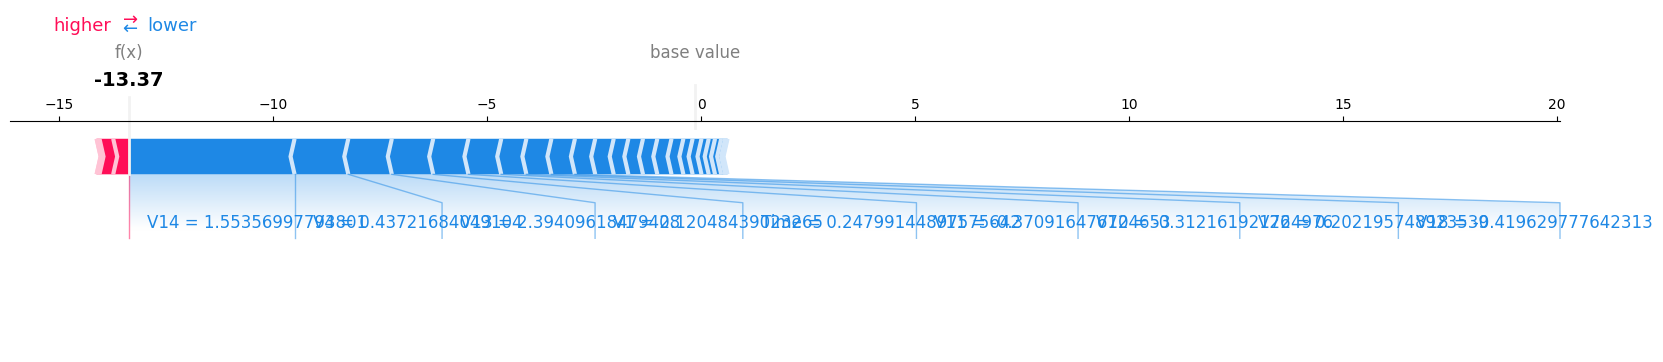

In [ ]:
shap.initjs()

row_index = 0

base_value = explainer.expected_value

# Handle different SHAP output formats
if isinstance(base_value, (list, np.ndarray)):
    base_value = np.asarray(base_value).flatten()[-1]

shap.force_plot(
    base_value,
    shap_values[row_index],
    X_explain.iloc[row_index],
    matplotlib=True
)

Evaluating Logistic Regression...
Evaluating Random Forest...
Evaluating XGBoost Weighted...
Evaluating XGBoost + SMOTE...


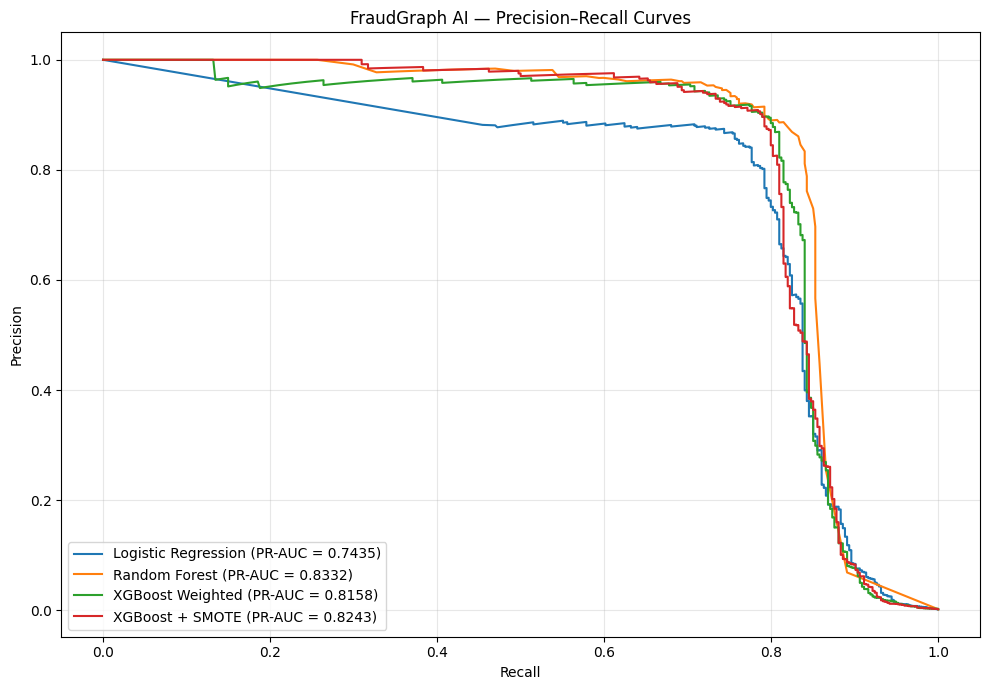

✅ Graph saved to: /content/drive/MyDrive/FraudGraph-AI/models/precision_recall_curves.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve, average_precision_score

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")

# Load training data
X_train = pd.read_csv(PROJECT / "data/processed/X_train.csv")
y_train = pd.read_csv(PROJECT / "data/processed/y_train.csv").squeeze()
y_train = np.asarray(y_train).ravel()

# Use the four models defined earlier in your notebook
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

plt.figure(figsize=(10, 7))

for name, candidate_model in models.items():
    print(f"Evaluating {name}...")

    probabilities = cross_val_predict(
        candidate_model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_train,
        probabilities
    )

    pr_auc = average_precision_score(y_train, probabilities)

    plt.plot(
        recall,
        precision,
        label=f"{name} (PR-AUC = {pr_auc:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("FraudGraph AI — Precision–Recall Curves")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the figure
output_path = PROJECT / "models/precision_recall_curves.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ Graph saved to: {output_path}")

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving FraudGraph_AI_Phase3_Completion.zip to FraudGraph_AI_Phase3_Completion.zip


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import zipfile

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")
ZIP_NAME = "FraudGraph_AI_Phase3_Completion.zip"

# Search common locations first
search_locations = [
    Path.cwd() / ZIP_NAME,
    Path("/content") / ZIP_NAME,
    PROJECT / ZIP_NAME,
    Path("/content/drive/MyDrive") / ZIP_NAME,
]

ZIP_PATH = next(
    (path.resolve() for path in search_locations if path.is_file()),
    None
)

# If not found, search the Colab working directory and Drive
if ZIP_PATH is None:
    for root in [Path("/content"), Path("/content/drive/MyDrive")]:
        matches = list(root.glob(f"**/{ZIP_NAME}"))
        if matches:
            ZIP_PATH = matches[0]
            break

if ZIP_PATH is None:
    print("❌ ZIP not found.")
    print("Current working directory:", Path.cwd())
    print("Upload the ZIP again using files.upload().")
else:
    print("✅ ZIP found:", ZIP_PATH)

    PROJECT.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        # Extract directly into MyDrive because the archive
        # contains a top-level FraudGraph-AI folder.
        archive.extractall("/content/drive/MyDrive")

    print("✅ Phase 3 files extracted successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ ZIP found: /content/drive/My Drive/FraudGraph-AI/FraudGraph_AI_Phase3_Completion.zip
✅ Phase 3 files extracted successfully!


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")

required_files = [
    "src/ml/predict.py",
    "src/api/schemas.py",
    "src/api/routes.py",
    "src/api/main.py",
    "tests/test_predictions.py",
]

for filename in required_files:
    path = PROJECT / filename
    print(("✅ FOUND" if path.exists() else "❌ MISSING"), filename)

✅ FOUND src/ml/predict.py
✅ FOUND src/api/schemas.py
✅ FOUND src/api/routes.py
✅ FOUND src/api/main.py
✅ FOUND tests/test_predictions.py


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")
TEST_FILE = PROJECT / "tests/test_predictions.py"

test_code = '''
from fastapi.testclient import TestClient

from src.api.main import app
from src.api.routes import get_predictor


class FakePredictor:
    threshold = 0.3247971534729004
    feature_names = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount"]
    metadata = {"model_name": "Fake XGBoost", "model_version": "test"}

    def predict_one(self, features):
        return {
            "probability": 0.42,
            "is_fraud": True,
            "risk_level": "medium"
        }

    def predict_batch(self, transactions):
        return [self.predict_one(item) for item in transactions]


def valid_transaction():
    transaction = {"Time": 10.0, "Amount": 20.0}
    transaction.update({f"V{i}": 0.0 for i in range(1, 29)})
    return transaction


def override_predictor():
    return FakePredictor()


app.dependency_overrides[get_predictor] = override_predictor


def test_health_returns_ok():
    with TestClient(app) as client:
        response = client.get("/health")

    assert response.status_code == 200
    assert response.json()["status"] == "ok"


def test_valid_prediction_returns_probability_in_range():
    with TestClient(app) as client:
        response = client.post("/predict", json=valid_transaction())

    assert response.status_code == 200

    result = response.json()
    assert 0 <= result["probability"] <= 1
    assert isinstance(result["is_fraud"], bool)
    assert result["risk_level"] in {"low", "medium", "high"}


def test_missing_fields_return_422():
    with TestClient(app) as client:
        response = client.post(
            "/predict",
            json={"Time": 10.0, "Amount": 20.0}
        )

    assert response.status_code == 422


def test_batch_prediction_works():
    payload = {
        "transactions": [
            valid_transaction(),
            valid_transaction()
        ]
    }

    with TestClient(app) as client:
        response = client.post("/predict/batch", json=payload)

    assert response.status_code == 200

    result = response.json()
    assert result["count"] == 2
    assert len(result["predictions"]) == 2


def test_model_info():
    with TestClient(app) as client:
        response = client.get("/model/info")

    assert response.status_code == 200
    assert response.json()["feature_count"] == 30
'''

TEST_FILE.write_text(test_code.strip() + "\\n", encoding="utf-8")

print("✅ Test file written:", TEST_FILE)
print("File size:", TEST_FILE.stat().st_size, "bytes")

✅ Test file written: /content/drive/MyDrive/FraudGraph-AI/tests/test_predictions.py
File size: 2281 bytes


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")
TEST_FILE = PROJECT / "tests/test_predictions.py"

# Remove any accidental literal "\n" characters at the end of the file
content = TEST_FILE.read_text(encoding="utf-8")
content = content.rstrip()

while content.endswith(r"\n"):
    content = content[:-2].rstrip()

TEST_FILE.write_text(content + "\n", encoding="utf-8")

print("✅ Fixed the test file.")
print("Last 10 lines:")
print("\n".join(TEST_FILE.read_text().splitlines()[-10:]))

✅ Fixed the test file.
Last 10 lines:
    assert result["count"] == 2
    assert len(result["predictions"]) == 2


def test_model_info():
    with TestClient(app) as client:
        response = client.get("/model/info")

    assert response.status_code == 200
    assert response.json()["feature_count"] == 30


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")
MAIN_FILE = PROJECT / "src/api/main.py"

print("File:", MAIN_FILE)
print("Exists:", MAIN_FILE.exists())
print("\nContents:\n")
print(MAIN_FILE.read_text(encoding="utf-8"))

File: /content/drive/MyDrive/FraudGraph-AI/src/api/main.py
Exists: True

Contents:




In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")

for filename in [
    "src/api/main.py",
    "src/api/routes.py",
    "src/api/schemas.py",
    "src/api/__init__.py",
    "src/ml/predict.py",
]:
    path = PROJECT / filename
    print(f"\n{'✅' if path.exists() else '❌'} {filename}")

    if path.exists():
        print("Size:", path.stat().st_size, "bytes")


✅ src/api/main.py
Size: 0 bytes

✅ src/api/routes.py
Size: 0 bytes

✅ src/api/schemas.py
Size: 0 bytes

✅ src/api/__init__.py
Size: 0 bytes

✅ src/ml/predict.py
Size: 0 bytes


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")

files = {}

# --------------------------------------------------
# 1. Prediction module
# --------------------------------------------------
files["src/ml/predict.py"] = '''
import json
import os
from pathlib import Path

import joblib
import pandas as pd

FEATURE_NAMES = (
    ["Time"] +
    [f"V{i}" for i in range(1, 29)] +
    ["Amount"]
)

# Risk categories based on predicted fraud probability:
# Low:    probability < 0.30
# Medium: 0.30 <= probability < 0.70
# High:   probability >= 0.70

RISK_LOW_MAX = 0.30
RISK_MEDIUM_MAX = 0.70


class FraudPredictor:
    """Load the trained model and metadata once."""

    def __init__(self, model_path=None, metadata_path=None):
        project = Path(
            os.getenv(
                "FRAUDGRAPH_PROJECT_DIR",
                str(Path(__file__).resolve().parents[2])
            )
        )

        self.model_path = Path(model_path) if model_path else (
            project / "models" / "transaction_model.joblib"
        )
        self.metadata_path = Path(metadata_path) if metadata_path else (
            project / "models" / "model_metadata.json"
        )

        if not self.model_path.is_file():
            raise FileNotFoundError(f"Model not found: {self.model_path}")

        if not self.metadata_path.is_file():
            raise FileNotFoundError(
                f"Metadata not found: {self.metadata_path}"
            )

        self.model = joblib.load(self.model_path)

        with open(self.metadata_path, encoding="utf-8") as file:
            self.metadata = json.load(file)

        threshold = self.metadata.get("threshold")

        if threshold is None:
            threshold = self.metadata.get("test_metrics", {}).get("threshold")

        if threshold is None:
            raise ValueError("No decision threshold found in model metadata.")

        self.threshold = float(threshold)

        if not 0 <= self.threshold <= 1:
            raise ValueError("Threshold must be between 0 and 1.")

        self.feature_names = FEATURE_NAMES

    @staticmethod
    def validate_features(features):
        if not isinstance(features, dict):
            raise ValueError("Transaction features must be a dictionary.")

        missing = [
            name for name in FEATURE_NAMES
            if name not in features
        ]

        extra = [
            name for name in features
            if name not in FEATURE_NAMES
        ]

        if missing:
            raise ValueError(
                "Missing required features: " + ", ".join(missing)
            )

        if extra:
            raise ValueError(
                "Unexpected features: " + ", ".join(extra)
            )

        for name in FEATURE_NAMES:
            try:
                value = float(features[name])
            except (TypeError, ValueError) as exc:
                raise ValueError(f"{name} must be numeric.") from exc

            if not pd.notna(value) or value in (float("inf"), float("-inf")):
                raise ValueError(f"{name} must be a finite number.")

    @staticmethod
    def risk_level(probability):
        if probability < RISK_LOW_MAX:
            return "low"
        if probability < RISK_MEDIUM_MAX:
            return "medium"
        return "high"

    def predict_one(self, features):
        self.validate_features(features)

        row = {
            name: float(features[name])
            for name in FEATURE_NAMES
        }

        X = pd.DataFrame([row], columns=FEATURE_NAMES)
        probability = float(self.model.predict_proba(X)[0, 1])
        probability = min(1.0, max(0.0, probability))

        return {
            "probability": probability,
            "is_fraud": probability >= self.threshold,
            "risk_level": self.risk_level(probability),
        }

    def predict_batch(self, transactions):
        if not transactions:
            raise ValueError("Batch must contain at least one transaction.")

        for index, transaction in enumerate(transactions):
            try:
                self.validate_features(transaction)
            except ValueError as exc:
                raise ValueError(
                    f"Transaction {index}: {exc}"
                ) from exc

        rows = [
            {name: float(item[name]) for name in FEATURE_NAMES}
            for item in transactions
        ]

        X = pd.DataFrame(rows, columns=FEATURE_NAMES)
        probabilities = self.model.predict_proba(X)[:, 1]

        results = []

        for probability in probabilities:
            probability = float(probability)
            probability = min(1.0, max(0.0, probability))

            results.append({
                "probability": probability,
                "is_fraud": probability >= self.threshold,
                "risk_level": self.risk_level(probability),
            })

        return results
'''

# --------------------------------------------------
# 2. Pydantic schemas
# --------------------------------------------------
files["src/api/schemas.py"] = '''
from typing import Literal

from pydantic import BaseModel, ConfigDict, Field


class TransactionInput(BaseModel):
    model_config = ConfigDict(extra="forbid")

    Time: float
    V1: float
    V2: float
    V3: float
    V4: float
    V5: float
    V6: float
    V7: float
    V8: float
    V9: float
    V10: float
    V11: float
    V12: float
    V13: float
    V14: float
    V15: float
    V16: float
    V17: float
    V18: float
    V19: float
    V20: float
    V21: float
    V22: float
    V23: float
    V24: float
    V25: float
    V26: float
    V27: float
    V28: float
    Amount: float = Field(..., ge=0)


class PredictionResponse(BaseModel):
    probability: float = Field(..., ge=0, le=1)
    is_fraud: bool
    risk_level: Literal["low", "medium", "high"]


class BatchRequest(BaseModel):
    transactions: list[TransactionInput] = Field(
        ..., min_length=1, max_length=1000
    )


class BatchResponse(BaseModel):
    predictions: list[PredictionResponse]
    count: int


class ModelInfoResponse(BaseModel):
    model_name: str
    model_version: str
    threshold: float
    feature_count: int
    feature_names: list[str]
    risk_cutoffs: dict[str, float]
'''

# --------------------------------------------------
# 3. API routes
# --------------------------------------------------
files["src/api/routes.py"] = '''
from fastapi import APIRouter, Depends, HTTPException, Request

from src.api.schemas import (
    TransactionInput,
    PredictionResponse,
    BatchRequest,
    BatchResponse,
    ModelInfoResponse,
)
from src.ml.predict import FraudPredictor, RISK_LOW_MAX, RISK_MEDIUM_MAX

router = APIRouter()


def get_predictor(request: Request):
    predictor = getattr(request.app.state, "predictor", None)

    if predictor is None:
        raise HTTPException(
            status_code=503,
            detail="Prediction model is not available."
        )

    return predictor


@router.get("/health")
def health(request: Request):
    ready = getattr(request.app.state, "predictor", None) is not None

    return {
        "status": "ok",
        "model": "ready" if ready else "not_loaded"
    }


@router.get("/model/info", response_model=ModelInfoResponse)
def model_info(predictor: FraudPredictor = Depends(get_predictor)):
    metadata = predictor.metadata

    return {
        "model_name": str(
            metadata.get("model_name", metadata.get("model", "XGBoost"))
        ),
        "model_version": str(
            metadata.get("model_version", metadata.get("version", "1.0.0"))
        ),
        "threshold": predictor.threshold,
        "feature_count": len(predictor.feature_names),
        "feature_names": predictor.feature_names,
        "risk_cutoffs": {
            "low_max_exclusive": RISK_LOW_MAX,
            "medium_max_exclusive": RISK_MEDIUM_MAX,
        },
    }


@router.post("/predict", response_model=PredictionResponse)
def predict(
    transaction: TransactionInput,
    predictor: FraudPredictor = Depends(get_predictor),
):
    try:
        return predictor.predict_one(transaction.model_dump())
    except ValueError as exc:
        raise HTTPException(status_code=400, detail=str(exc)) from exc
    except Exception as exc:
        raise HTTPException(
            status_code=500,
            detail="Prediction failed."
        ) from exc


@router.post("/predict/batch", response_model=BatchResponse)
def predict_batch(
    request: BatchRequest,
    predictor: FraudPredictor = Depends(get_predictor),
):
    try:
        predictions = predictor.predict_batch(
            [item.model_dump() for item in request.transactions]
        )

        return {
            "predictions": predictions,
            "count": len(predictions),
        }
    except ValueError as exc:
        raise HTTPException(status_code=400, detail=str(exc)) from exc
    except Exception as exc:
        raise HTTPException(
            status_code=500,
            detail="Batch prediction failed."
        ) from exc
'''

# --------------------------------------------------
# 4. FastAPI application
# --------------------------------------------------
files["src/api/main.py"] = '''
import logging
from contextlib import asynccontextmanager

from fastapi import FastAPI
from fastapi.middleware.cors import CORSMiddleware

from src.api.routes import router
from src.ml.predict import FraudPredictor

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("fraudgraph.api")


@asynccontextmanager
async def lifespan(app: FastAPI):
    # Load the model and metadata once when the server starts.
    try:
        app.state.predictor = FraudPredictor()
        logger.info("FraudGraph AI model loaded successfully.")
    except Exception:
        app.state.predictor = None
        logger.exception("Could not load the prediction model.")
    yield
    app.state.predictor = None


app = FastAPI(
    title="FraudGraph AI API",
    description="Transaction fraud prediction service",
    version="1.0.0",
    lifespan=lifespan,
)

app.add_middleware(
    CORSMiddleware,
    allow_origins=["http://localhost:3000"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)

app.include_router(router)
'''

# --------------------------------------------------
# 5. API tests
# --------------------------------------------------
files["tests/test_predictions.py"] = '''
from fastapi.testclient import TestClient

from src.api.main import app
from src.api.routes import get_predictor


class FakePredictor:
    threshold = 0.3248
    feature_names = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount"]
    metadata = {"model_name": "Fake XGBoost", "model_version": "test"}

    def predict_one(self, features):
        return {
            "probability": 0.42,
            "is_fraud": True,
            "risk_level": "medium",
        }

    def predict_batch(self, transactions):
        return [self.predict_one(item) for item in transactions]


def valid_transaction():
    data = {"Time": 10.0, "Amount": 20.0}
    data.update({f"V{i}": 0.0 for i in range(1, 29)})
    return data


def override_predictor():
    return FakePredictor()


app.dependency_overrides[get_predictor] = override_predictor


def test_health_returns_ok():
    with TestClient(app) as client:
        response = client.get("/health")

    assert response.status_code == 200
    assert response.json()["status"] == "ok"


def test_valid_prediction_returns_probability_in_range():
    with TestClient(app) as client:
        response = client.post("/predict", json=valid_transaction())

    assert response.status_code == 200
    result = response.json()
    assert 0 <= result["probability"] <= 1
    assert isinstance(result["is_fraud"], bool)
    assert result["risk_level"] in {"low", "medium", "high"}


def test_missing_fields_return_422():
    with TestClient(app) as client:
        response = client.post(
            "/predict",
            json={"Time": 10.0, "Amount": 20.0},
        )

    assert response.status_code == 422


def test_batch_prediction_works():
    payload = {
        "transactions": [valid_transaction(), valid_transaction()]
    }

    with TestClient(app) as client:
        response = client.post("/predict/batch", json=payload)

    assert response.status_code == 200
    assert response.json()["count"] == 2
    assert len(response.json()["predictions"]) == 2


def test_model_info():
    with TestClient(app) as client:
        response = client.get("/model/info")

    assert response.status_code == 200
    assert response.json()["feature_count"] == 30
'''

# Write only the Phase 3 files.
for relative_path, content in files.items():
    path = PROJECT / relative_path
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(content.strip() + "\n", encoding="utf-8")
    print(f"✅ Wrote {relative_path}: {path.stat().st_size} bytes")

print("\nPhase 3 source files restored.")

✅ Wrote src/ml/predict.py: 4681 bytes
✅ Wrote src/api/schemas.py: 1193 bytes
✅ Wrote src/api/routes.py: 2636 bytes
✅ Wrote src/api/main.py: 1048 bytes
✅ Wrote tests/test_predictions.py: 2202 bytes

Phase 3 source files restored.


In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI

import subprocess
import os
import time

# Start the API server in the background
log_file = open("/tmp/fraudgraph_api.log", "w")

server = subprocess.Popen(
    [
        "python", "-m", "uvicorn",
        "src.api.main:app",
        "--host", "0.0.0.0",
        "--port", "8000"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(5)

print("Server process ID:", server.pid)
print("Server running:", server.poll() is None)

with open("/tmp/fraudgraph_api.log", "r") as f:
    print(f.read())

/content/drive/MyDrive/FraudGraph-AI
Server process ID: 76512
Server running: True
INFO:     Started server process [76512]
INFO:     Waiting for application startup.
INFO:fraudgraph.api:FraudGraph AI model loaded successfully.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)



In [ ]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8000/health",
        timeout=10
    )

    print("Status code:", response.status_code)
    print("Response:", response.json())

except requests.exceptions.RequestException as error:
    print("Connection error:", error)

Status code: 200
Response: {'status': 'ok', 'model': 'ready'}


In [ ]:
import requests

# Create two sample transactions
transaction1 = {
    "Time": 10,
    "Amount": 20.0
}

transaction2 = {
    "Time": 500,
    "Amount": 150.0
}

# Add V1 to V28 features to both transactions
for i in range(1, 29):
    transaction1[f"V{i}"] = 0.0
    transaction2[f"V{i}"] = 0.0

# Send both transactions in one request
try:
    response = requests.post(
        "http://127.0.0.1:8000/predict/batch",
        json={
            "transactions": [transaction1, transaction2]
        },
        timeout=30
    )

    print("Status code:", response.status_code)
    print("Batch prediction response:")
    print(response.json())

except requests.exceptions.RequestException as error:
    print("Connection error:", error)

Status code: 200
Batch prediction response:
{'predictions': [{'probability': 1.28717817915458e-06, 'is_fraud': False, 'risk_level': 'low'}, {'probability': 1.0176847808907041e-06, 'is_fraud': False, 'risk_level': 'low'}], 'count': 2}


In [ ]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8000/model/info",
        timeout=10
    )

    print("Status code:", response.status_code)
    print("Model information:")

    data = response.json()
    print(data)

except requests.exceptions.RequestException as error:
    print("Connection error:", error)

Status code: 200
Model information:
{'model_name': 'xgb_weighted', 'model_version': '3.4.1', 'threshold': 0.3247971534729004, 'feature_count': 30, 'feature_names': ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount'], 'risk_cutoffs': {'low_max_exclusive': 0.3, 'medium_max_exclusive': 0.7}}


In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI

!python -m pytest tests/test_predictions.py -v

/content/drive/MyDrive/FraudGraph-AI
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/drive/MyDrive/FraudGraph-AI
plugins: anyio-4.15.1, typeguard-4.6.0, platformdirs-4.13.5, langsmith-0.14.12
collected 5 items                                                              

tests/test_predictions.py::test_health_returns_ok PASSED                 [ 20%]
tests/test_predictions.py::test_valid_prediction_returns_probability_in_range PASSED [ 40%]
tests/test_predictions.py::test_missing_fields_return_422 PASSED         [ 60%]
tests/test_predictions.py::test_batch_prediction_works PASSED            [ 80%]
tests/test_predictions.py::test_model_info PASSED                        [100%]

============================== 5 passed in 3.00s ===============================


In [ ]:
!curl -s http://127.0.0.1:8000/health

{"status":"ok","model":"ready"}

In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI
!python -m uvicorn src.api.main:app --host 0.0.0.0 --port 8000

/content/drive/MyDrive/FraudGraph-AI
INFO:     Started server process [91906]
INFO:     Waiting for application startup.
INFO:fraudgraph.api:FraudGraph AI model loaded successfully.
INFO:     Application startup complete.
ERROR:    [Errno 98] error while attempting to bind on address ('0.0.0.0', 8000): address already in use
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.


In [ ]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8000/health",
        timeout=5
    )
    print("Status:", response.status_code)
    print("Response:", response.json())

except requests.exceptions.RequestException as e:
    print("Connection error:", e)

Status: 200
Response: {'status': 'ok', 'model': 'ready'}


In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI

!grep -RniE "api.?key|HTTPBearer|HTTPBasic|Authorization|APIKeyHeader" src/api

/content/drive/MyDrive/FraudGraph-AI


In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI

!grep -RniE "api.?key|HTTPBearer|HTTPBasic|Authorization|APIKeyHeader" src/api

/content/drive/MyDrive/FraudGraph-AI


In [ ]:
import os
import subprocess

project = "/content/drive/MyDrive/FraudGraph-AI"

result = subprocess.run(
    [
        "grep", "-RniE",
        "api.?key|HTTPBearer|HTTPBasic|Authorization|APIKeyHeader",
        os.path.join(project, "src/api")
    ],
    capture_output=True,
    text=True
)

if result.stdout.strip():
    print(result.stdout)
else:
    print("No authentication mechanisms found in src/api.")

if result.stderr.strip():
    print("Warnings:", result.stderr)

No authentication mechanisms found in src/api.


In [ ]:
import os
import secrets

api_key = secrets.token_urlsafe(32)
os.environ["FRAUDGRAPH_API_KEY"] = api_key

print("API key created for this Colab runtime.")
print("Keep it private. Do not share it or commit it to GitHub.")

API key created for this Colab runtime.
Keep it private. Do not share it or commit it to GitHub.


In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/FraudGraph-AI")

for filename in [
    "src/api/main.py",
    "src/api/routes.py",
    "src/api/schemas.py",
]:
    path = project / filename
    print(f"\n{'=' * 20} {filename} {'=' * 20}")
    print(path.read_text())


==================== src/api/main.py ====================
import logging
from contextlib import asynccontextmanager

from fastapi import FastAPI
from fastapi.middleware.cors import CORSMiddleware

from src.api.routes import router
from src.ml.predict import FraudPredictor

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("fraudgraph.api")


@asynccontextmanager
async def lifespan(app: FastAPI):
    # Load the model and metadata once when the server starts.
    try:
        app.state.predictor = FraudPredictor()
        logger.info("FraudGraph AI model loaded successfully.")
    except Exception:
        app.state.predictor = None
        logger.exception("Could not load the prediction model.")
    yield
    app.state.predictor = None


app = FastAPI(
    title="FraudGraph AI API",
    description="Transaction fraud prediction service",
    version="1.0.0",
    lifespan=lifespan,
)

app.add_middleware(
    CORSMiddleware,
    allow_origins=["http://localhost:3000"],
 

In [ ]:
from pathlib import Path
import ast

project = Path("/content/drive/MyDrive/FraudGraph-AI")
main_file = project / "src/api/main.py"

code = main_file.read_text()

try:
    ast.parse(code)
    print("✅ main.py syntax is valid")
except SyntaxError as e:
    print(f"❌ Syntax error on line {e.lineno}: {e.msg}")

required_items = [
    "APIKeyHeader",
    "verify_api_key",
    "FRAUDGRAPH_API_KEY",
    "FraudPredictor",
    "CORSMiddleware",
    "app.include_router",
]

print("\nChecking authentication setup:")
for item in required_items:
    print(f"{'✅' if item in code else '❌'} {item}")

print("\nFile location:", main_file)

✅ main.py syntax is valid

Checking authentication setup:
❌ APIKeyHeader
❌ verify_api_key
❌ FRAUDGRAPH_API_KEY
✅ FraudPredictor
✅ CORSMiddleware
✅ app.include_router

File location: /content/drive/MyDrive/FraudGraph-AI/src/api/main.py


In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/FraudGraph-AI")
main_file = project / "src/api/main.py"

code = '''
import logging
import os
import secrets
from contextlib import asynccontextmanager

from fastapi import FastAPI, HTTPException, Request, Security, Depends
from fastapi.middleware.cors import CORSMiddleware
from fastapi.security import APIKeyHeader

from src.api.routes import router
from src.ml.predict import FraudPredictor

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("fraudgraph.api")

api_key_header = APIKeyHeader(
    name="X-API-Key",
    auto_error=False,
)


async def verify_api_key(
    request: Request,
    api_key: str | None = Security(api_key_header),
):
    expected_key = os.environ.get("FRAUDGRAPH_API_KEY")

    if not expected_key:
        logger.error("FRAUDGRAPH_API_KEY is not configured.")
        raise HTTPException(
            status_code=503,
            detail="API authentication is not configured.",
        )

    if not api_key or not secrets.compare_digest(api_key, expected_key):
        raise HTTPException(
            status_code=401,
            detail="Invalid or missing API key.",
        )


@asynccontextmanager
async def lifespan(app: FastAPI):
    try:
        app.state.predictor = FraudPredictor()
        logger.info("FraudGraph AI model loaded successfully.")
    except Exception:
        app.state.predictor = None
        logger.exception("Could not load the prediction model.")

    yield
    app.state.predictor = None


app = FastAPI(
    title="FraudGraph AI API",
    description="Transaction fraud prediction service",
    version="1.0.0",
    lifespan=lifespan,
)

app.add_middleware(
    CORSMiddleware,
    allow_origins=[
        "http://localhost:5173",
        "http://127.0.0.1:5173",
    ],
    allow_credentials=False,
    allow_methods=["GET", "POST", "OPTIONS"],
    allow_headers=["Content-Type", "X-API-Key"],
)

app.include_router(
    router,
    dependencies=[Depends(verify_api_key)],
)
'''

main_file.write_text(code.strip() + "\n")

print("✅ Updated:", main_file)

✅ Updated: /content/drive/MyDrive/FraudGraph-AI/src/api/main.py


In [ ]:
import ast

code = main_file.read_text()
ast.parse(code)

for item in [
    "APIKeyHeader",
    "verify_api_key",
    "FRAUDGRAPH_API_KEY",
    "FraudPredictor",
    "CORSMiddleware",
]:
    print(("✅ " if item in code else "❌ ") + item)

print("\n✅ Python syntax is valid")

✅ APIKeyHeader
✅ verify_api_key
✅ FRAUDGRAPH_API_KEY
✅ FraudPredictor
✅ CORSMiddleware

✅ Python syntax is valid


In [ ]:
import os
import secrets

# Generate a private key for this Colab session.
api_key = secrets.token_urlsafe(32)

# Make it available to the API process.
os.environ["FRAUDGRAPH_API_KEY"] = api_key

print("✅ API key generated and configured.")
print("Keep this key private. Do not publish it or commit it to GitHub.")

✅ API key generated and configured.
Keep this key private. Do not publish it or commit it to GitHub.


In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI

!python -c "import os; print('API key configured:', bool(os.environ.get('FRAUDGRAPH_API_KEY')))"

In [ ]:
!lsof -i :8000

COMMAND   PID USER   FD   TYPE  DEVICE SIZE/OFF NODE NAME
python3   681 root   63u  IPv4 2408609      0t0  TCP localhost:56524->localhost:8000 (CLOSE_WAIT)
python3 76512 root   12u  IPv4 1982511      0t0  TCP *:8000 (LISTEN)


In [ ]:
!fuser -k 8000/tcp

8000/tcp:            76512


In [ ]:
import os
import sys
import subprocess
import time
from pathlib import Path

project = Path("/content/drive/MyDrive/FraudGraph-AI")

# Confirm the API key exists in this notebook session.
assert os.environ.get("FRAUDGRAPH_API_KEY"), (
    "API key missing. Generate it again before continuing."
)

env = os.environ.copy()

server = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "uvicorn",
        "src.api.main:app",
        "--host",
        "127.0.0.1",
        "--port",
        "8000",
    ],
    cwd=str(project),
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)

time.sleep(3)

if server.poll() is not None:
    print("❌ Server stopped during startup:")
    print(server.stdout.read())
else:
    print("✅ API server started.")
    print("Process ID:", server.pid)
    print("Listening at http://127.0.0.1:8000")

✅ API server started.
Process ID: 95716
Listening at http://127.0.0.1:8000


In [ ]:
import requests

url = "http://127.0.0.1:8000/health"

# Request without the API key
r1 = requests.get(url, timeout=10)
print("Without API key:", r1.status_code, r1.json())

# Request with the API key
r2 = requests.get(
    url,
    headers={"X-API-Key": os.environ["FRAUDGRAPH_API_KEY"]},
    timeout=10,
)
print("With API key:", r2.status_code, r2.json())

Without API key: 401 {'detail': 'Invalid or missing API key.'}
With API key: 200 {'status': 'ok', 'model': 'ready'}


In [ ]:
!lsof -i :8000

COMMAND   PID USER   FD   TYPE  DEVICE SIZE/OFF NODE NAME
python3   681 root   63u  IPv4 2408609      0t0  TCP localhost:56524->localhost:8000 (CLOSE_WAIT)
python3   681 root   65u  IPv4 2496940      0t0  TCP localhost:43166->localhost:8000 (CLOSE_WAIT)
python3   681 root   66u  IPv4 2498092      0t0  TCP localhost:43168->localhost:8000 (CLOSE_WAIT)
python3 95716 root   12u  IPv4 2495397      0t0  TCP localhost:8000 (LISTEN)


In [ ]:
import os
import requests

API_URL = "http://127.0.0.1:8000"
API_KEY = os.environ["FRAUDGRAPH_API_KEY"]

headers = {
    "X-API-Key": API_KEY,
    "Content-Type": "application/json",
}

# Create a synthetic transaction with all 30 required features.
transaction = {
    "Time": 10.0,
    "Amount": 20.0,
}

for i in range(1, 29):
    transaction[f"V{i}"] = 0.0

response = requests.post(
    f"{API_URL}/predict",
    headers=headers,
    json=transaction,
    timeout=30,
)

print("HTTP status:", response.status_code)
print("Prediction:", response.json())

HTTP status: 200
Prediction: {'probability': 1.28717817915458e-06, 'is_fraud': False, 'risk_level': 'low'}


In [ ]:
import os
import requests

API_URL = "http://127.0.0.1:8000"
HEADERS = {
    "X-API-Key": os.environ["FRAUDGRAPH_API_KEY"]
}

# Test 1: Model information
response = requests.get(
    f"{API_URL}/model/info",
    headers=HEADERS,
    timeout=15
)

print("Model info status:", response.status_code)
print(response.json())

# Test 2: Batch prediction
transaction = {"Time": 10.0, "Amount": 20.0}

for i in range(1, 29):
    transaction[f"V{i}"] = 0.0

response = requests.post(
    f"{API_URL}/predict/batch",
    headers=HEADERS,
    json={"transactions": [transaction, transaction]},
    timeout=30
)

print("\nBatch prediction status:", response.status_code)
print(response.json())

Model info status: 200
{'model_name': 'xgb_weighted', 'model_version': '3.4.1', 'threshold': 0.3247971534729004, 'feature_count': 30, 'feature_names': ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount'], 'risk_cutoffs': {'low_max_exclusive': 0.3, 'medium_max_exclusive': 0.7}}

Batch prediction status: 200
{'predictions': [{'probability': 1.28717817915458e-06, 'is_fraud': False, 'risk_level': 'low'}, {'probability': 1.28717817915458e-06, 'is_fraud': False, 'risk_level': 'low'}], 'count': 2}


In [ ]:
import os
import subprocess
import time
import re
from pathlib import Path

# Download the Cloudflare Tunnel executable
binary = "/content/cloudflared"

if not os.path.exists(binary):
    subprocess.run(
        [
            "wget", "-q",
            "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
            "-O", binary
        ],
        check=True
    )
    os.chmod(binary, 0o755)

# Start a temporary tunnel to the authenticated FastAPI server
log_path = "/content/cloudflared.log"

with open(log_path, "w") as log_file:
    tunnel = subprocess.Popen(
        [
            binary,
            "tunnel",
            "--url", "http://127.0.0.1:8000",
            "--no-autoupdate"
        ],
        stdout=log_file,
        stderr=subprocess.STDOUT
    )

# Wait for Cloudflare to assign a temporary URL
tunnel_url = None

for _ in range(30):
    time.sleep(2)

    if tunnel.poll() is not None:
        print("Tunnel process stopped. Check the logs below.")
        print(Path(log_path).read_text()[-3000:])
        break

    log_text = Path(log_path).read_text()

    match = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        log_text
    )

    if match:
        tunnel_url = match.group(0)
        break

if tunnel_url:
    print("Temporary tunnel URL:", tunnel_url)
    print("Tunnel process ID:", tunnel.pid)
else:
    print("Tunnel URL not found. Recent logs:")
    print(Path(log_path).read_text()[-3000:])

Temporary tunnel URL: https://becoming-ensure-rough-thank.trycloudflare.com
Tunnel process ID: 98775


In [ ]:
print("API key configured:", bool(os.environ.get("FRAUDGRAPH_API_KEY")))

In [ ]:
import os
print("API key configured:", bool(os.environ.get("FRAUDGRAPH_API_KEY")))

In [ ]:
import subprocess
from pathlib import Path

log_path = Path("/content/cloudflared.log")

print("Tunnel log exists:", log_path.exists())

if log_path.exists():
    print(log_path.read_text()[-4000:])

print("\nTunnel processes:")
subprocess.run(["pgrep", "-af", "cloudflared"])

Tunnel log exists: True
ector ID: 5d1cce6f-d0e5-4093-b9b1-5495a3bfc25a
2026-10-28T19:35:08Z INF Initial protocol quic
2026-10-28T19:35:08Z INF ICMP proxy will use 172.28.0.12 as source for IPv4
2026-10-28T19:35:08Z INF ICMP proxy will use ::1 in zone lo as source for IPv6
2026/10/28 19:35:08 failed to sufficiently increase receive buffer size (was: 208 kiB, wanted: 7168 kiB, got: 416 kiB). See https://github.com/quic-go/quic-go/wiki/UDP-Buffer-Sizes for details.
2026-10-28T19:35:08Z INF ICMP proxy will use 172.28.0.12 as source for IPv4
2026-10-28T19:35:08Z INF ICMP proxy will use ::1 in zone lo as source for IPv6
2026-10-28T19:35:08Z INF Starting metrics server on 127.0.0.1:20241/metrics
2026-10-28T19:35:08Z INF Tunnel connection curve preferences: [X25519MLKEM768 CurveID(65074) CurveP256] connIndex=0 event=0 ip=198.41.200.233
2026-10-28T19:35:09Z INF Registered tunnel connection connIndex=0 connection=e4694cce-a769-4a3c-82de-b087e16407c1 event=0 ip=198.41.200.233 location=sea07 proto

CompletedProcess(args=['pgrep', '-af', 'cloudflared'], returncode=0)

In [ ]:
import requests

response = requests.get(
    "http://127.0.0.1:8000/health",
    headers={"X-API-Key": os.environ["FRAUDGRAPH_API_KEY"]},
    timeout=10,
)

print("Status:", response.status_code)
print("Response:", response.json())


Status: 200
Response: {'status': 'ok', 'model': 'ready'}


In [ ]:
import subprocess
import time
import re
from pathlib import Path

binary = "/content/cloudflared"
log_path = "/content/cloudflared.log"

# Stop any previous tunnel process.
subprocess.run(
    ["pkill", "-f", r"cloudflared tunnel --url"],
    check=False,
)

time.sleep(2)

# Start a fresh tunnel.
with open(log_path, "w") as log_file:
    tunnel = subprocess.Popen(
        [
            binary,
            "tunnel",
            "--url", "http://127.0.0.1:8000",
            "--no-autoupdate",
        ],
        stdout=log_file,
        stderr=subprocess.STDOUT,
    )

# Wait for the new URL.
tunnel_url = None

for _ in range(30):
    time.sleep(2)

    if tunnel.poll() is not None:
        print("Tunnel stopped. Recent logs:")
        print(Path(log_path).read_text()[-2500:])
        break

    logs = Path(log_path).read_text()
    match = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        logs,
    )

    if match:
        tunnel_url = match.group(0)
        break

if tunnel_url:
    print("New tunnel URL:", tunnel_url)
    print("Tunnel process ID:", tunnel.pid)
else:
    print("No tunnel URL found.")
    print(Path(log_path).read_text()[-2500:])

New tunnel URL: https://yield-departmental-gui-lbs.trycloudflare.com
Tunnel process ID: 102058


In [ ]:
import os
import requests

url = "https://yield-departmental-gui-lbs.trycloudflare.com"

response = requests.get(
    f"{url}/health",
    headers={
        "X-API-Key": os.environ["FRAUDGRAPH_API_KEY"]
    },
    timeout=20,
)

print("Status:", response.status_code)
print("Response:", response.text)

Status: 200
Response: {"status":"ok","model":"ready"}


In [ ]:
import os
import requests

key = os.environ.get("FRAUDGRAPH_API_KEY")

print("API key exists:", bool(key))

try:
    r = requests.get(
        "http://127.0.0.1:8000/health",
        headers={"X-API-Key": key} if key else {},
        timeout=10,
    )
    print("Backend status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("Backend connection error:", str(e))

API key exists: True
Backend status: 200
Response: {"status":"ok","model":"ready"}


In [ ]:
import subprocess
import time
import re
from pathlib import Path

binary = "/content/cloudflared"
log_path = "/content/cloudflared.log"

# Stop the previous tunnel, if any.
subprocess.run(
    ["pkill", "-f", r"cloudflared tunnel --url"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)
time.sleep(2)

with open(log_path, "w") as log:
    tunnel = subprocess.Popen(
        [
            binary,
            "tunnel",
            "--url", "http://127.0.0.1:8000",
            "--no-autoupdate",
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
    )

tunnel_url = None

for _ in range(30):
    time.sleep(2)

    if tunnel.poll() is not None:
        print("Tunnel stopped:")
        print(Path(log_path).read_text()[-2000:])
        break

    match = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        Path(log_path).read_text(),
    )

    if match:
        tunnel_url = match.group(0)
        break

if tunnel_url:
    print("New tunnel URL:", tunnel_url)
    print("Tunnel PID:", tunnel.pid)
else:
    print("No URL found. Check the logs:")
    print(Path(log_path).read_text()[-2000:])

New tunnel URL: https://guns-documentation-witness-reads.trycloudflare.com
Tunnel PID: 104248


In [ ]:
import os

print("Current directory:", os.getcwd())

print("\nSearching for model files...")

for root, dirs, files in os.walk("/content/drive/MyDrive/FraudGraph-AI"):
    for file in files:
        if file in ["transaction_model.joblib", "model_metadata.json"]:
            print(os.path.join(root, file))

Current directory: /content/drive/MyDrive/FraudGraph-AI

Searching for model files...
/content/drive/MyDrive/FraudGraph-AI/models/transaction_model.joblib
/content/drive/MyDrive/FraudGraph-AI/models/model_metadata.json


In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/FraudGraph-AI/models/transaction_model.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/FraudGraph-AI/models/model_metadata.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%pip install "uvicorn[standard]" fastapi

In [ ]:
import os

project_path = "/content/drive/MyDrive/FraudGraph-AI"

print("Project exists:", os.path.isdir(project_path))

for folder in ["src/api", "src/ml", "models"]:
    path = os.path.join(project_path, folder)
    print(f"\n{folder}:")
    if os.path.isdir(path):
        print(os.listdir(path))
    else:
        print("Folder not found")

Project exists: True

src/api:
['__init__.py', 'main.py', 'schemas.py', 'routes.py', '__pycache__']

src/ml:
['__init__.py', 'train.py', 'evaluate.py', 'predict.py', '__pycache__']

models:
['.gitkeep', 'transaction_model.joblib', 'model_metadata.json', 'precision_recall_curves.png']


In [ ]:
%cd /content/drive/MyDrive/FraudGraph-AI
!python -m uvicorn src.api.main:app --host 0.0.0.0 --port 8000

/content/drive/MyDrive/FraudGraph-AI
INFO:     Started server process [111887]
INFO:     Waiting for application startup.
INFO:fraudgraph.api:FraudGraph AI model loaded successfully.
INFO:     Application startup complete.
ERROR:    [Errno 98] error while attempting to bind on address ('0.0.0.0', 8000): address already in use
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.


In [ ]:
import requests

url = "http://127.0.0.1:8000/health"

try:
    response = requests.get(url, timeout=10)
    print("Status code:", response.status_code)
    print("Response:", response.text)
except requests.RequestException as e:
    print("API request failed:", e)

Status code: 401
Response: {"detail":"Invalid or missing API key."}


In [ ]:
import os

key = os.environ.get("FRAUDGRAPH_API_KEY")

if key:
    print("API key is configured.")
    print("Key length:", len(key))
else:
    print("FRAUDGRAPH_API_KEY is not configured in this runtime.")

API key is configured.
Key length: 43


In [ ]:
import os
import requests

key = os.environ["FRAUDGRAPH_API_KEY"]

response = requests.get(
    "http://127.0.0.1:8000/health",
    headers={"X-API-Key": key},
    timeout=10,
)

print("Status code:", response.status_code)
print("Response:", response.text)

Status code: 200
Response: {"status":"ok","model":"ready"}


In [ ]:
import os
import requests

api_key = os.environ["FRAUDGRAPH_API_KEY"]

response = requests.get(
    "http://127.0.0.1:8000/model/info",
    headers={"X-API-Key": api_key},
    timeout=10,
)

print("Status:", response.status_code)

if response.ok:
    print(response.json())
else:
    print(response.text)

Status: 200
{'model_name': 'xgb_weighted', 'model_version': '3.4.1', 'threshold': 0.3247971534729004, 'feature_count': 30, 'feature_names': ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount'], 'risk_cutoffs': {'low_max_exclusive': 0.3, 'medium_max_exclusive': 0.7}}


In [ ]:
import os
import requests

API_URL = "http://127.0.0.1:8000"
API_KEY = os.environ["FRAUDGRAPH_API_KEY"]

# Synthetic test transaction with all 30 required features.
features = {
    "Time": 10.0,
    **{f"V{i}": 0.0 for i in range(1, 29)},
    "Amount": 20.0,
}

response = requests.post(
    f"{API_URL}/predict",
    headers={"X-API-Key": API_KEY},
    json=features,
    timeout=30,
)

print("Status:", response.status_code)
print("Response:", response.text)

Status: 200
Response: {"probability":1.28717817915458e-6,"is_fraud":false,"risk_level":"low"}


In [ ]:
import os
import requests

API_URL = "http://127.0.0.1:8000"
API_KEY = os.environ["FRAUDGRAPH_API_KEY"]

features = {
    "Time": 10.0,
    **{f"V{i}": 0.0 for i in range(1, 29)},
    "Amount": 20.0,
}

response = requests.post(
    f"{API_URL}/predict/batch",
    headers={"X-API-Key": API_KEY},
    json={"transactions": [features, features]},
    timeout=30,
)

print("Status:", response.status_code)
print("Response:", response.text)

Status: 200
Response: {"predictions":[{"probability":1.28717817915458e-6,"is_fraud":false,"risk_level":"low"},{"probability":1.28717817915458e-6,"is_fraud":false,"risk_level":"low"}],"count":2}


In [ ]:
import subprocess

result = subprocess.run(
    ["bash", "-lc", "pgrep -af cloudflared || true"],
    capture_output=True,
    text=True,
)

print(result.stdout or "No cloudflared process found.")

104248 /content/cloudflared tunnel --url http://127.0.0.1:8000 --no-autoupdate
112792 bash -lc pgrep -af cloudflared || true



In [ ]:
import subprocess
import re

result = subprocess.run(
    ["bash", "-lc", "grep -oE 'https://[a-zA-Z0-9.-]+\\.trycloudflare\\.com' /tmp/cloudflared.log | tail -1"],
    capture_output=True,
    text=True,
)

url = result.stdout.strip()

if url:
    print("Cloudflare URL:", url)
else:
    print("URL not found in /tmp/cloudflared.log")
    print("Check the terminal output of the running cloudflared process.")

URL not found in /tmp/cloudflared.log
Check the terminal output of the running cloudflared process.


In [ ]:
import subprocess

result = subprocess.run(
    ["bash", "-lc", "ps -p 104248 -o pid=,args="],
    capture_output=True,
    text=True,
)

print(result.stdout or "Cloudflare process not found.")

 104248 /content/cloudflared tunnel --url http://127.0.0.1:8000 --no-autoupdate



In [ ]:
import subprocess

result = subprocess.run(
    ["bash", "-lc", "ps -p 104248 -o pid=,lstart=,args="],
    capture_output=True,
    text=True,
)

print(result.stdout)

 104248 Wed Oct 28 19:57:42 2026 /content/cloudflared tunnel --url http://127.0.0.1:8000 --no-autoupdate



In [ ]:
import subprocess
import time
import os
import signal

# Stop only the old Cloudflare process.
subprocess.run(
    ["bash", "-lc", "kill 104248"],
    check=False,
)

time.sleep(2)

# Start a new tunnel and capture its output.
log_file = open("/content/cloudflared.log", "w")

process = subprocess.Popen(
    [
        "/content/cloudflared",
        "tunnel",
        "--url",
        "http://127.0.0.1:8000",
        "--no-autoupdate",
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True,
)

print("New Cloudflare process started:", process.pid)
print("Waiting for the public URL...")

New Cloudflare process started: 113422
Waiting for the public URL...


In [ ]:
import time
import re

log_path = "/content/cloudflared.log"
url = None

for _ in range(20):
    time.sleep(1)

    with open(log_path, "r") as file:
        logs = file.read()

    match = re.search(
        r"https://[a-zA-Z0-9.-]+\.trycloudflare\.com",
        logs,
    )

    if match:
        url = match.group(0)
        break

if url:
    print("Cloudflare URL:", url)
else:
    print("URL not found yet. Recent logs:")
    print(logs[-3000:])

Cloudflare URL: https://ceramic-eds-circular-associations.trycloudflare.com


In [ ]:
import os
import requests

BASE_URL = "https://ceramic-eds-circular-associations.trycloudflare.com"
API_KEY = os.environ["FRAUDGRAPH_API_KEY"]

response = requests.get(
    f"{BASE_URL}/health",
    headers={"X-API-Key": API_KEY},
    timeout=20,
)

print("Status:", response.status_code)
print("Response:", response.text)

Status: 200
Response: {"status":"ok","model":"ready"}


In [ ]:
import requests
import os

response = requests.get(
    "http://127.0.0.1:8000/health",
    headers={"X-API-Key": os.environ["FRAUDGRAPH_API_KEY"]},
    timeout=10,
)

print("FastAPI status:", response.status_code)
print("Response:", response.text)

FastAPI status: 200
Response: {"status":"ok","model":"ready"}


In [ ]:
import subprocess

result = subprocess.run(
    ["bash", "-lc", "pgrep -af cloudflared || true"],
    capture_output=True,
    text=True,
)

print(result.stdout)

104248 [cloudflared] <defunct>
113422 /content/cloudflared tunnel --url http://127.0.0.1:8000 --no-autoupdate
114705 bash -lc pgrep -af cloudflared || true



In [ ]:
from pathlib import Path

log = Path("/content/cloudflared.log")

if log.exists():
    print(log.read_text(errors="ignore")[-4000:])
else:
    print("Tunnel log file not found.")

nnector ID: 1311c429-8ccc-4afa-b619-13351c698791
2026-10-28T20:35:37Z INF Initial protocol quic
2026-10-28T20:35:37Z INF ICMP proxy will use 172.28.0.12 as source for IPv4
2026-10-28T20:35:37Z INF ICMP proxy will use ::1 in zone lo as source for IPv6
2026/10/28 20:35:37 failed to sufficiently increase receive buffer size (was: 208 kiB, wanted: 7168 kiB, got: 416 kiB). See https://github.com/quic-go/quic-go/wiki/UDP-Buffer-Sizes for details.
2026-10-28T20:35:37Z INF ICMP proxy will use 172.28.0.12 as source for IPv4
2026-10-28T20:35:37Z INF ICMP proxy will use ::1 in zone lo as source for IPv6
2026-10-28T20:35:37Z INF Starting metrics server on 127.0.0.1:20241/metrics
2026-10-28T20:35:37Z INF Tunnel connection curve preferences: [X25519MLKEM768 CurveID(65074) CurveP256] connIndex=0 event=0 ip=198.41.200.43
2026-10-28T20:35:37Z INF Registered tunnel connection connIndex=0 connection=170decd5-9223-45f9-b231-83973ff371b0 event=0 ip=198.41.200.43 location=sea09 protocol=quic
2026-10-28T20:3

In [ ]:
import re
import time
from pathlib import Path

log_path = Path("/content/cloudflared.log")

for attempt in range(10):
    if log_path.exists():
        logs = log_path.read_text(errors="ignore")
        urls = re.findall(
            r"https://[a-zA-Z0-9.-]+\.trycloudflare\.com",
            logs,
        )

        if urls:
            print("Latest Cloudflare URL:", urls[-1])
            break

    time.sleep(1)
else:
    print("No public URL found in the log.")
    print(logs[-3000:] if log_path.exists() else "Log file missing.")

Latest Cloudflare URL: https://ceramic-eds-circular-associations.trycloudflare.com


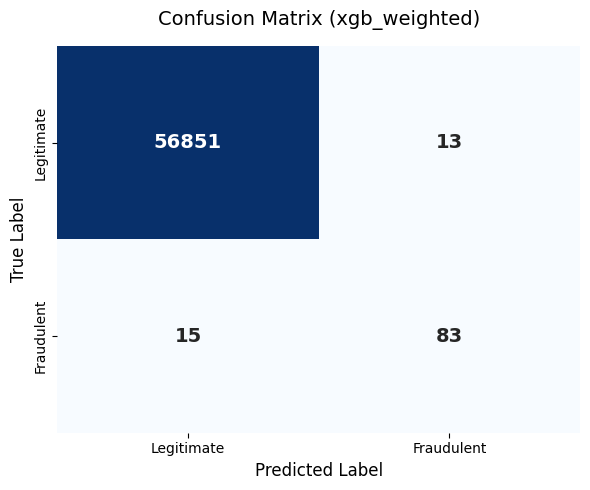

             MODEL PERFORMANCE REPORT
Selected Model:      xgb_weighted
Decision Threshold:  0.324797
--------------------------------------------------
PR-AUC Score:        88.7884%
ROC-AUC Score:       96.9870%
Precision:           86.4583%
Recall:              84.6939%
F1-Score:            85.5670%


In [ ]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define project directory
PROJECT = Path("/content/drive/MyDrive/FraudGraph-AI")
metadata_path = PROJECT / "models/model_metadata.json"

# Load metadata
with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

test_metrics = metadata["test_metrics"]

# Safely extract the model name
model_name = metadata.get("selected_model", metadata.get("model_name", "XGBoost (Weighted)"))

# Extract confusion matrix values
tn = test_metrics["tn"]
fp = test_metrics["fp"]
fn = test_metrics["fn"]
tp = test_metrics["tp"]

cm = np.array([[tn, fp], [fn, tp]])

# Plot the Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"],
    cbar=False,
    annot_kws={"size": 14, "weight": "bold"}
)

plt.title(f"Confusion Matrix ({model_name})", fontsize=14, pad=15)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.tight_layout()
plt.show()

# Print Detailed Performance Metrics
print("=" * 50)
print("             MODEL PERFORMANCE REPORT")
print("=" * 50)
print(f"Selected Model:      {model_name}")
print(f"Decision Threshold:  {test_metrics['threshold']:.6f}")
print("-" * 50)
print(f"PR-AUC Score:        {test_metrics['pr_auc']:.4%}")
print(f"ROC-AUC Score:       {test_metrics['roc_auc']:.4%}")
print(f"Precision:           {test_metrics['precision']:.4%}")
print(f"Recall:              {test_metrics['recall']:.4%}")
print(f"F1-Score:            {test_metrics['f1']:.4%}")
print("=" * 50)
